# Figure 7 — Full-coverage (1.0) nav_to_pose office runs around the obstacle

For each selected run (coverage == 1.0, i.e. *all* 22 declared tree nodes were reached, including every recovery behaviour) we overlay on the cropped `secorolab` map:
- the **static obstacle** box (size + orientation + pose from the test config),
- the **robot** circle at its pose of *closest approach* to the obstacle (from `sim_poses.csv`, base_link frame),
- the **goal pose** (arrow),
- the full travelled path.

The check that ends this notebook answers: did the robot pass the obstacle, and did it reach the goal?


In [46]:
from __future__ import annotations
import csv, json, yaml
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
import matplotlib.colors as mcolors
from matplotlib.patches import Polygon, Circle
from PIL import Image

DATA_ROOT = Path("/home/sam/Downloads/ICRA analysis")
OPT = DATA_ROOT / "optimization_tests"
CAMP = (OPT / "qd-nav-to-pose-secorolab-2026-09-08-01140915.incomplete"
             / "qd-nav-to-pose-secorolab-2026-09-08-01140915")

SINGLE_COLUMN = 3.4
TWO_COLUMNS = 7.0
plt.style.use(str(DATA_ROOT / "ieee.txt"))
mpl.rcParams["figure.dpi"] = 110

# ---- secorolab map (world -> pixel) ----
def load_map(pgm_path, origin, res):
    img = np.asarray(Image.open(pgm_path), dtype=np.float32)
    rows, cols = img.shape
    def w2p(x, y):
        return (np.asarray(x) - origin[0]) / res, \
               (origin[1] + rows * res - np.asarray(y)) / res
    return img, w2p

SECO, seco_w2p = load_map(
    CAMP / "_config" / "environments" / "secorolab" / "maps" / "secorolab.pgm",
    (-7.2, -7.75), 0.05)

ROBOT_R = 0.175       # drawn turtlebot circle radius (m)
OBS_HALF = 0.25      # 0.5 x 0.5 obstacle box, half-extents
GOAL_TOL = 0.5       # reach-goal threshold (m)


### Helper: declared node set + per-run coverage (identical to `figures.ipynb`)

In [47]:
def parse_bt_xml(xml_path):
    """Flatten a BehaviorTree.CPP XML the way RoboVAST does."""
    from xml.etree import ElementTree
    root = ElementTree.parse(xml_path).getroot()
    trees = {bt.get("ID"): bt for bt in root.iter("BehaviorTree")}
    main_id = root.get("main_tree_to_execute")
    main = trees.get(main_id) if main_id else None
    if main is None:
        main = next(iter(trees.values()), None)
    name_of = lambda el: el.get("name") or el.tag
    names = []
    def walk(el, pid, active):
        names.append(name_of(el)); me = len(names) - 1
        for ch in list(el):
            if ch.tag == "SubTree":
                ref = ch.get("ID"); sub = trees.get(ref)
                if sub is not None and ref not in active:
                    for sc in list(sub):
                        walk(sc, me, active | {ref})
                continue
            walk(ch, me, active)
    for ch in list(main):
        walk(ch, None, frozenset({main_id} if main_id else set()))
    return names

DECLARED = set(parse_bt_xml(
    CAMP / "_config" / "files" / "navigate_to_pose_w_replanning_and_recovery.xml"))
print(f"{len(DECLARED)} declared nodes: {sorted(DECLARED)}")

def run_coverage(cfg_name, run_idx):
    csvp = CAMP / cfg_name / str(run_idx) / "nav2_behaviors.csv"
    reached = set()
    with open(csvp) as f:
        for row in csv.DictReader(f):
            if row.get("status_name", "") not in ("INVALID", "IDLE", ""):
                reached.add(row["behavior_name"])
    return len(reached & DECLARED) / len(DECLARED)

def sim_path(cfg_name, run_idx):
    xs, ys = [], []
    with open(CAMP / cfg_name / str(run_idx) / "sim_poses.csv") as f:
        for row in csv.DictReader(f):
            if row.get("frame") != "base_link":
                continue
            xs.append(float(row["position.x"])); ys.append(float(row["position.y"]))
    return np.array([xs, ys]) if len(xs) >= 2 else None

def sim_path_yaw(cfg_name, run_idx):
    """Trimmed (path, yaw) from sim_poses.csv (base_link rows, teleport-stripped)."""
    xs, ys, yaws = [], [], []
    with open(CAMP / cfg_name / str(run_idx) / "sim_poses.csv") as f:
        for row in csv.DictReader(f):
            if row.get("frame") != "base_link":
                continue
            xs.append(float(row["position.x"])); ys.append(float(row["position.y"]))
            qz = float(row["orientation.z"]); qw = float(row["orientation.w"])
            qx = float(row["orientation.x"]); qy = float(row["orientation.y"])
            yaws.append(float(np.arctan2(2.0 * (qw*qz + qx*qy), 1.0 - 2.0*(qy*qy + qz*qz))))
    path = np.array([xs, ys]) if len(xs) >= 2 else None
    yaw = np.array(yaws) if len(yaws) >= 2 else None
    if path is None:
        return None, None
    d = np.linalg.norm(np.diff(path, axis=1), axis=0)
    jumps = np.where(d > TELEPORT_M)[0]
    if len(jumps) == 0:
        return path, yaw
    k = int(jumps[0]) + 1
    return path[:, k:], yaw[k:]

from rosbags.rosbag2 import Reader
from rosbags.typesys import Stores, get_typestore
_PLAN_TYPE = get_typestore(Stores.ROS2_FOXY)

def last_plan(cfg_name, run_idx):
    """(2,N) global plan from the most recent /plan message (map frame)."""
    rdir = CAMP / cfg_name / str(run_idx) / "rosbag2"
    poses = None
    with Reader(rdir.as_posix()) as reader:
        cmap = {c.topic: c for c in reader.connections}["/plan"]
        for conn, ts, raw in reader.messages(connections=[cmap]):
            poses = _PLAN_TYPE.deserialize_cdr(raw, cmap.msgtype).poses
    if not poses:
        return None
    return np.array([[p.pose.position.x for p in poses],
                     [p.pose.position.y for p in poses]])

TELEPORT_M = 1.0
def trim_teleport(pth):
    """Strip leading spawn-idle + teleport prefix."""
    if pth is None or pth.shape[1] < 2:
        return pth
    d = np.linalg.norm(np.diff(pth, axis=1), axis=0)
    jumps = np.where(d > TELEPORT_M)[0]
    if len(jumps) == 0:
        return pth
    return pth[:, int(jumps[0]) + 1:]


22 declared nodes: ['BackUp', 'ClearGlobalCostmap-Context', 'ClearGlobalCostmap-Subtree', 'ClearLocalCostmap-Context', 'ClearLocalCostmap-Subtree', 'ClearingActions', 'ComputePathToPose', 'ControllerSelector', 'Fallback', 'FollowPath', 'GoalUpdated', 'NavigateRecovery', 'NavigateWithReplanning', 'PlannerSelector', 'RateController', 'RecoveryActions', 'RecoveryFallback', 'Sequence', 'Spin', 'Wait', 'WouldAControllerRecoveryHelp', 'WouldAPlannerRecoveryHelp']


### Select 4 runs with coverage == 1.0 (strict), one per config

In [48]:
# full-coverage runs that have a *static* obstacle, grouped by config dir
FULL = [
    ("ce6fd04b66985-1-1-1-1-1-1-1-1-1-1-1", 0),
    ("cbcf83ab6a5a2-1-1-1-1-1-1-1-1-1-1-1", 0),
    ("c64c2240f82c6-1-1-1-1-1-1-1-1-1-1-1", 3),
    ("cf3d7041dfa4a-1-1-1-1-1-1-1-1-1-1-1", 4),
]
assert all(run_coverage(c, r) == 1.0 for c, r in FULL), "expected coverage == 1.0"

for cfg, run in FULL:
    print(f"{cfg[:8]} run {run}: coverage = {run_coverage(cfg, run):.3f}")


ce6fd04b run 0: coverage = 1.000
cbcf83ab run 0: coverage = 1.000
c64c2240 run 3: coverage = 1.000
cf3d7041 run 4: coverage = 1.000


### Per-run extraction: obstacle, start, goal, robot path, analysis

In [49]:
def box_dist(points, center, yaw, half=OBS_HALF):
    """Distance from each point to the rotated square box surface."""
    d = points.T - center
    c, s = np.cos(yaw), np.sin(yaw)
    local = d @ np.array([[c, -s], [s, c]])
    return np.hypot(np.maximum(np.abs(local[:, 0]) - half, 0),
                    np.maximum(np.abs(local[:, 1]) - half, 0))

rows = []
for cfg, run in FULL:
    scen = yaml.safe_load(open(CAMP / cfg / "_config" / "scenario.config"))["test_scenario"]

    # obstacle (size + orientation + pose from the test)
    o = scen["static_objects"][0]
    op = o["spawn_pose"]
    obs_pos = np.array([op["position"]["x"], op["position"]["y"]])
    obs_yaw = op["orientation"]["yaw"]
    import re
    _w = float(re.search(r"width:=([-0-9.]+)", o["xacro_arguments"]).group(1))
    _l = float(re.search(r"length:=([-0-9.]+)", o["xacro_arguments"]).group(1))
    obs_size = (_w, _l)

    start = np.array([scen["start_pose"]["position"]["x"],
                      scen["start_pose"]["position"]["y"]])
    start_yaw = scen["start_pose"]["orientation"]["yaw"]
    goal = np.array([scen["goal_pose"]["position"]["x"],
                     scen["goal_pose"]["position"]["y"]])
    goal_yaw = scen["goal_pose"]["orientation"]["yaw"]

    path, path_yaw = sim_path_yaw(cfg, run)
    dbox = box_dist(path, obs_pos, obs_yaw, max(obs_size) / 2)
    ia = int(np.argmin(dbox))                 # robot pose of closest approach to obstacle
    closest = path[:, -1]                     # final robot pose
    closest_yaw = float(path_yaw[-1])

    plan = last_plan(cfg, run)                # last /plan (global) path

    # passed obstacle? dot(path - obs, start->goal unit) beyond the box far side
    u = (goal - start) / np.linalg.norm(goal - start)
    proj = (path.T - obs_pos) @ u
    pass_thresh = (np.max(np.abs(obs_size)) / 2 + ROBOT_R)
    passed = bool(proj.max() > pass_thresh and proj.min() < -pass_thresh)

    # reached goal? min distance between any travelled point and goal pose
    dg = np.linalg.norm(path.T - goal, axis=1)
    reached = bool(dg.min() < GOAL_TOL)
    endg = float(np.linalg.norm(path[:, -1] - goal))

    rows.append(dict(cfg=cfg, run=run, coverage=run_coverage(cfg, run),
                     obs_pos=obs_pos, obs_yaw=obs_yaw, obs_size=obs_size,
                     start=start, start_yaw=start_yaw,
                     goal=goal, goal_yaw=goal_yaw, path=path,
                     closest=closest, dbox_min=float(dbox.min()), dgoal_min=float(dg.min()),
                     endg=endg, passed=passed, reached=reached,
                     closest_yaw=closest_yaw, plan=plan))

print(f"{'cfg':8} {'run':>3} {'cov':>5} | {'obstacle':>16} {'yaw':>6} | "
      f"{'final-pose':>16} {'boxd':>6} {'goalDmin':>8} {'endgoal':>7} | {'passed':>6} {'reach':>6}")
for r in rows:
    print(f"{r['cfg'][:8]} {r['run']:>3} {r['coverage']:5.2f} | "
          f"{str(tuple(np.round(r['obs_pos'],2))):>16} {r['obs_yaw']:6.2f} | "
          f"{str(tuple(np.round(r['closest'],2))):>16} {r['dbox_min']:6.2f} "
          f"{r['dgoal_min']:8.2f} {r['endg']:7.2f} | "
          f"{('YES' if r['passed'] else 'no '):>6} {('YES' if r['reached'] else 'no '):>6}")


cfg      run   cov |         obstacle    yaw |       final-pose   boxd goalDmin endgoal | passed  reach
ce6fd04b   0  1.00 |   (-0.63, -3.08)   1.94 |   (-1.05, -3.43)   0.26     1.79    2.03 |    YES    no 
cbcf83ab   0  1.00 |     (0.05, 3.82)  -2.50 |    (-0.15, 3.07)   0.32     2.56    2.70 |    no     no 
c64c2240   3  1.00 |    (-0.61, -3.1)   1.94 |    (-0.1, -3.81)   0.40     2.27    2.55 |    YES    no 
cf3d7041   4  1.00 |   (-1.45, -1.39)  -2.50 |   (-0.05, -2.25)   1.32     2.84    3.52 |    no     no 


### Figure: 2×2 cropped map views (obstacle + robot closest pose + goal)

saved: /home/sam/Downloads/ICRA analysis/fig7_full_coverage_obstacle.png


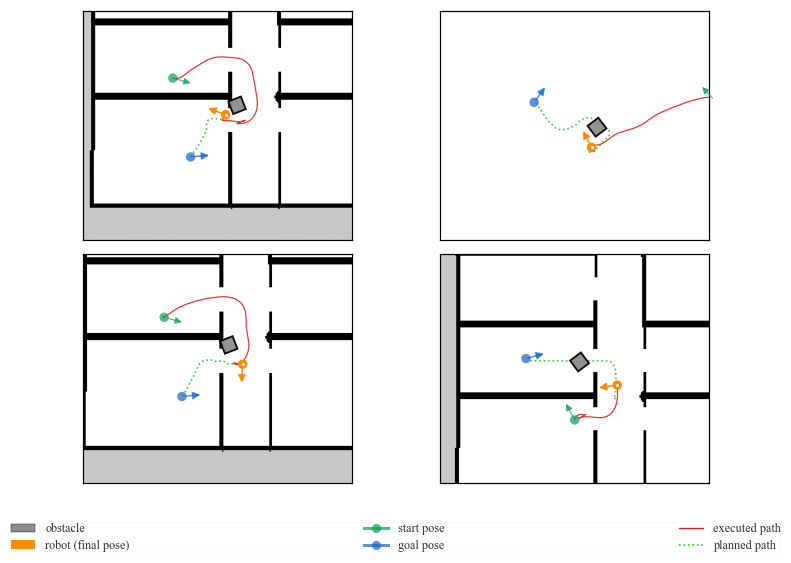

In [58]:
def obs_corners(pos, yaw, size):
    """World-coord corners of the rotated obstacle box (Nx2)."""
    c, s = np.cos(yaw), np.sin(yaw); hx, hy = size[0]/2, size[1]/2
    R = np.array([[c, -s], [s, c]])
    half = np.array([[+hx, +hy], [+hx, -hy], [-hx, -hy], [-hx, +hy]])
    return pos[None, :] + (half @ R.T)

PAD = 3.3          # world-space padding around the region of interest (m)
ARROW_LEN = 0.8      # length of orientation arrows (m)

# one identical crop window for every subfigure, centred on each run's ROI
regions = np.array([np.vstack([r["obs_pos"], r["closest"], r["goal"]]) for r in rows])
mids = regions.mean(axis=1)
H = regions.ptp(axis=1).max(axis=0) / 2 + PAD   # common half-extents (x, y)

fig, axs = plt.subplots(2, 2, figsize=(TWO_COLUMNS, TWO_COLUMNS * 0.72))

for ax, r, mid in zip(axs.ravel(), rows, mids):
    # ---- crop window around obstacle + closest pose + goal ----
    lo = mid - H; hi = mid + H
    width, height = hi - lo

    # ---- draw the (cropped) map ----
    pxl, pxy = seco_w2p(lo[0], hi[1])   # top-left pixel
    prx, pry = seco_w2p(hi[0], lo[1])   # bottom-right pixel
    crop = SECO[int(pxy):int(pry), int(pxl):int(prx)]
    ax.imshow(crop, cmap="gray", origin="upper", aspect="auto",
              extent=[lo[0], hi[0], lo[1], hi[1]])

    # ---- planned global path to goal (dotted) ----
    if r["plan"] is not None:
        ax.plot(r["plan"][0], r["plan"][1], ":", color="#32CD32", lw=1.1,
                alpha=0.95, zorder=2)

    # ---- travelled path (axis is in world coords via extent) ----
    ax.plot(r["path"][0], r["path"][1], "-", color="#e02020", lw=0.8, alpha=0.9, zorder=3)

    # ---- obstacle box (rotated) ----
    corners = obs_corners(r["obs_pos"], r["obs_yaw"], r["obs_size"])
    ax.add_patch(Polygon(corners, closed=True, facecolor="#8c8c8c", edgecolor="black",
                         lw=1.2, alpha=0.95, zorder=5))

    # ---- robot at closest approach ----
    ax.add_patch(Circle(r["closest"], ROBOT_R, facecolor="#FF8C00",
                        edgecolor="none", zorder=6))
    ax.plot(*r["closest"], marker="o", ms=2, color="w", zorder=7)
    # orientation arrow at final robot pose (bright blue)
    ax.annotate("", xy=(r["closest"][0] + ARROW_LEN*np.cos(r["closest_yaw"]),
                        r["closest"][1] + ARROW_LEN*np.sin(r["closest_yaw"])),
                xytext=(r["closest"][0], r["closest"][1]),
                arrowprops=dict(arrowstyle="-|>", color="#FF8C00", lw=1.0,
                mutation_scale=10), zorder=7)

    # ---- goal pose (arrow) ----
    gx, gy = r["goal"]
    ux, uy = np.cos(r["goal_yaw"]), np.sin(r["goal_yaw"])
    ax.annotate("", xy=(gx + ARROW_LEN*ux, gy + ARROW_LEN*uy), xytext=(gx, gy),
                arrowprops=dict(arrowstyle="-|>", color="#1866c4", lw=1.0,
                                mutation_scale=10, alpha=0.7), zorder=8)
    ax.add_patch(Circle((gx, gy), ROBOT_R, facecolor="#1866c4",
                        edgecolor="none", alpha=0.7, zorder=8))

    # start pose ring + black orientation arrow
    sx, sy = r["start"]
    ax.add_patch(Circle((sx, sy), ROBOT_R, facecolor="#0f9d58",
                        edgecolor="none", alpha=0.7, zorder=6))
    ax.annotate("", xy=(sx + ARROW_LEN*np.cos(r["start_yaw"]),
                        sy + ARROW_LEN*np.sin(r["start_yaw"])),
                xytext=(sx, sy),
                arrowprops=dict(arrowstyle="-|>", color="#0f9d58", lw=0.8,
                                mutation_scale=9, alpha=0.7), zorder=6)

    ax.set_xlim(lo[0], hi[0]); ax.set_ylim(lo[1], hi[1])
    ax.set_aspect("equal")

    # ---- visible border on each subfigure ----
    for _sp in ax.spines.values():
        _sp.set_visible(True)
        _sp.set_color("black")
        _sp.set_linewidth(0.8)
    ax.set_xticks([])
    ax.set_yticks([])

from matplotlib.patches import Patch
from matplotlib.lines import Line2D

# ---- figure legend (obstacle / robot / goal) ----
handles = [
    Patch(facecolor="#8c8c8c", edgecolor="black", label="obstacle"),
    Circle((0, 0), 0.5, facecolor="#FF8C00", edgecolor="none",
           label="robot (final pose)"),
    Line2D([0, 1], [0, 0], color="#0f9d58", lw=2.0, marker="o", ms=6,
           mfc="#0f9d58", mec="none", alpha=0.7, label="start pose"),
    Line2D([0, 1], [0, 0], color="#1866c4", lw=2.0, marker="o", ms=6,
           mfc="#1866c4", mec="none", alpha=0.7, label="goal pose"),
    Line2D([0, 1], [0, 0], color="#e02020", lw=0.9, label="executed path"),
    Line2D([0, 1], [0, 0], color="#32CD32", lw=1.1, ls=":", label="planned path"),
]
fig.legend(handles=handles, loc="lower center",
           bbox_to_anchor=(0.0, 0.0, 1.0, 0.0), mode="expand",
           ncol=3, frameon=True, fontsize=8, borderpad=0.0, borderaxespad=0.0)
fig.tight_layout(rect=(0, 0.10, 1, 1))

fout = DATA_ROOT / "fig7_full_coverage_obstacle.png"
fig.savefig(fout, dpi=300)
print(f"saved: {fout}")
plt.show()


fig_h=2.015 in  panels y=[0.273,0.975]  legend strip=[0,0.273]
saved: /home/sam/Downloads/ICRA analysis/fig7_two_panel_single_column.png


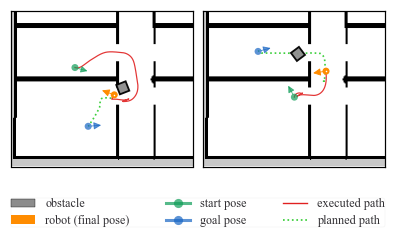

In [59]:
# ---- Figure 7 (2-panel): top-left + bottom-right runs, single-column ----

SEL = (0, 3)                       # indexes into rows (top-left, bottom-right)
sel = [rows[i] for i in SEL]

# ---- ONE shared crop window for BOTH panels covering every element of the
#      two runs (start, final, goal, obstacle, travelled + planned path) ----
BUFFER = 2.0                     # modest padding around the union of both runs
_sh = []
for _r in sel:
    _sh.append(_r["obs_pos"][:, None]); _sh.append(_r["start"][:, None])
    _sh.append(_r["goal"][:, None]);    _sh.append(_r["closest"][:, None])
    _sh.append(_r["path"])
    if _r["plan"] is not None:
        _sh.append(_r["plan"])
all_ = np.hstack(_sh)
c_lo = all_.min(axis=1) - BUFFER
c_hi = all_.max(axis=1) + BUFFER

# clamp to the map raster so imshow indices stay valid (map is visible)
_MAP_LO = np.array([-7.2, -7.75])
_MAP_HI = _MAP_LO + np.array([SECO.shape[1], SECO.shape[0]]) * 0.05
c_lo = np.maximum(c_lo, _MAP_LO)
c_hi = np.minimum(c_hi, _MAP_HI)

# keep the 2x2 world w/h aspect so panels stay shaped the same
_regions = np.array([np.vstack([r["obs_pos"], r["closest"], r["goal"]]) for r in rows])
H4 = _regions.ptp(axis=1).max(axis=0) / 2 + PAD
ratio = H4[0] / H4[1]
_w = c_hi[0] - c_lo[0]; _h = c_hi[1] - c_lo[1]
if _w / _h > ratio:                       # expand height to match ratio
    n_h = _w / ratio
    _cy = (c_lo[1] + c_hi[1]) / 2
    c_lo[1] = max(_MAP_LO[1], _cy - n_h / 2); c_hi[1] = min(_MAP_HI[1], _cy + n_h / 2)
else:                                     # expand width to match ratio
    n_w = _h * ratio
    _cx = (c_lo[0] + c_hi[0]) / 2
    c_lo[0] = max(_MAP_LO[0], _cx - n_w / 2); c_hi[0] = min(_MAP_HI[0], _cx + n_w / 2)
lo = c_lo; hi = c_hi                      # SAME crop used by both panels
H = (hi - lo) / 2

# panel loop uses the shared window
mid = (lo + hi) / 2

SAVE_DPI = 600
GAP_PX = 50.0
FIG_W_IN = SINGLE_COLUMN

# panel size so that (2*w + gap) fills the single-column width exactly
h_p = (FIG_W_IN - GAP_PX / SAVE_DPI) / (2 * ratio)
w_p = h_p * ratio

# figure height = legend strip + panel + small top margin (no overlap, no crop)
LEG_STRIP = 0.55          # inches reserved for the legend
TOP_MARGIN = 0.05         # inches above the panels
fig_h = LEG_STRIP + h_p + TOP_MARGIN
fig = plt.figure(figsize=(FIG_W_IN, fig_h))
fig.patch.set_facecolor("white")

w_fr, h_fr = w_p / FIG_W_IN, h_p / fig_h
gap_fr = GAP_PX / SAVE_DPI / FIG_W_IN
x0 = (FIG_W_IN - 2 * w_p - GAP_PX / SAVE_DPI) / 2 / FIG_W_IN
y0 = LEG_STRIP / fig_h
axs = [fig.add_axes([x0, y0, w_fr, h_fr]),
       fig.add_axes([x0 + w_fr + gap_fr, y0, w_fr, h_fr])]

for ax, r in zip(axs, sel):
    pxl, pxy = seco_w2p(lo[0], hi[1])
    prx, pry = seco_w2p(hi[0], lo[1])
    crop = SECO[int(pxy):int(pry), int(pxl):int(prx)]
    ax.imshow(crop, cmap="gray", origin="upper", aspect="auto",
              extent=[lo[0], hi[0], lo[1], hi[1]])

    if r["plan"] is not None:
        ax.plot(r["plan"][0], r["plan"][1], ":", color="#32CD32", lw=1.1,
                alpha=0.95, zorder=2)
    ax.plot(r["path"][0], r["path"][1], "-", color="#e02020", lw=0.8, alpha=0.9, zorder=3)

    corners = obs_corners(r["obs_pos"], r["obs_yaw"], r["obs_size"])
    ax.add_patch(Polygon(corners, closed=True, facecolor="#8c8c8c",
                         edgecolor="black", lw=1.2, alpha=0.95, zorder=5))

    ax.add_patch(Circle(r["closest"], ROBOT_R, facecolor="#FF8C00",
                        edgecolor="none", zorder=6))
    ax.plot(*r["closest"], marker=".", ms=2, color="w", zorder=7)
    ax.annotate("", xy=(r["closest"][0] + ARROW_LEN*np.cos(r["closest_yaw"]),
                        r["closest"][1] + ARROW_LEN*np.sin(r["closest_yaw"])),
                xytext=(r["closest"][0], r["closest"][1]),
                arrowprops=dict(arrowstyle="-|>", color="#FF8C00", lw=0.6,
                mutation_scale=10), zorder=7)

    gx, gy = r["goal"]
    ux, uy = np.cos(r["goal_yaw"]), np.sin(r["goal_yaw"])
    ax.annotate("", xy=(gx + ARROW_LEN*ux, gy + ARROW_LEN*uy), xytext=(gx, gy),
                arrowprops=dict(arrowstyle="-|>", color="#1866c4", lw=0.6,
                                mutation_scale=10, alpha=0.7), zorder=8)
    ax.add_patch(Circle((gx, gy), ROBOT_R, facecolor="#1866c4",
                        edgecolor="none", alpha=0.7, zorder=8))

    sx, sy = r["start"]
    ax.add_patch(Circle((sx, sy), ROBOT_R, facecolor="#0f9d58",
                        edgecolor="none", alpha=0.7, zorder=6))
    ax.annotate("", xy=(sx + ARROW_LEN*np.cos(r["start_yaw"]),
                        sy + ARROW_LEN*np.sin(r["start_yaw"])),
                xytext=(sx, sy),
                arrowprops=dict(arrowstyle="-|>", color="#0f9d58", lw=0.6,
                                mutation_scale=9, alpha=0.7), zorder=6)

    ax.set_xlim(lo[0], hi[0]); ax.set_ylim(lo[1], hi[1])
    ax.set_aspect("equal")
    for _sp in ax.spines.values():
        _sp.set_visible(True)
        _sp.set_color("black")
        _sp.set_linewidth(0.8)
    ax.set_xticks([])
    ax.set_yticks([])

from matplotlib.patches import Patch
from matplotlib.lines import Line2D
handles = [
    Patch(facecolor="#8c8c8c", edgecolor="black", label="obstacle"),
    Circle((0, 0), 0.5, facecolor="#FF8C00", edgecolor="none",
           label="robot (final pose)"),
    Line2D([0, 1], [0, 0], color="#0f9d58", lw=2.0, marker="o", ms=6,
           mfc="#0f9d58", mec="none", alpha=0.7, label="start pose"),
    Line2D([0, 1], [0, 0], color="#1866c4", lw=2.0, marker="o", ms=6,
           mfc="#1866c4", mec="none", alpha=0.7, label="goal pose"),
    Line2D([0, 1], [0, 0], color="#e02020", lw=0.9, label="executed path"),
    Line2D([0, 1], [0, 0], color="#32CD32", lw=1.1, ls=":", label="planned path"),
]
fig.legend(handles=handles, loc="lower center",
           bbox_to_anchor=(0.0, 0.0, 1.0, 0.0), mode="expand",
           ncol=3, frameon=True, fontsize=8, borderpad=0.0, borderaxespad=0.0)
print(f"fig_h={fig_h:.3f} in  panels y=[{y0:.3f},{y0 + h_p/fig_h:.3f}]  legend strip=[0,{LEG_STRIP/fig_h:.3f}]")
fout2 = DATA_ROOT / "fig7_two_panel_single_column.png"
fig.savefig(fout2, dpi=SAVE_DPI)
print(f"saved: {fout2}")
plt.show()


### Verdict

In [52]:
n_pass = sum(r["passed"] for r in rows)
n_goal = sum(r["reached"] for r in rows)
print(f"of the {len(rows)} full-coverage runs:")
print(f"  passed the obstacle      : {n_pass}/{len(rows)}")
print(f"  reached the goal pose    : {n_goal}/{len(rows)}")
print("Note: coverage == 1.0 means every declared node (incl. all recoveries) was reached;")
print("it does NOT imply the navigation goal was achieved.")


of the 4 full-coverage runs:
  passed the obstacle      : 2/4
  reached the goal pose    : 0/4
Note: coverage == 1.0 means every declared node (incl. all recoveries) was reached;
it does NOT imply the navigation goal was achieved.
